# 14 · Análisis exploratorio: las cuatro ideas juntas

**Etapa 17 del plan.** En el `13`, cada idea sola dio de +0,74 a +1,60 M sobre `ACH`, con un error de 1,2 o 1,3 M. Separarlas así sería decidir casi al azar. Este notebook prueba primero las cuatro juntas, con 5 semillas.

**Preguntas:**
1. ¿Cuánto da `ACH` con las cuatro ideas juntas?
2. Con 5 semillas de `ACH`, ¿cuánto queda de lo que dio cada candidata sola?

**Todo lo de este notebook es exploratorio.** No cambia el resultado de la regla pre-registrada.

**No carga 201909 ni 201910,** ni sus filas ni su clase. **No escribe en `exp/03/` a `exp/13/` ni en los `resultados/03_*` a `13_*`:** solo los lee.

Ficha: `fichas/etapa_17_cuatro_juntas.md` (en el laboratorio).

## 1. Parámetros

**Retomar:** si la corrida se corta, se vuelve a correr entera. Los modelos ya hechos no se repiten.

In [1]:
from pathlib import Path
import gc
import hashlib
import json
import resource
import sys
import time
import warnings

import duckdb
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter
from scipy import stats
from sklearn.metrics import roc_auc_score

# --- Parámetros -------------------------------------------------------------
BASE_PARQUET = Path('../data/base_2019.parquet')
RESULTADOS = Path('../resultados')
EXP_13 = Path('../exp/13')                          # solo se lee
EXP = Path('../exp/14')
FIGURAS = RESULTADOS / 'figuras'

MES_TOPE = 201908                                   # nada posterior entra a este notebook
MESES_BANCO = [201903, 201904, 201905, 201906, 201907, 201908]
MESES_CON_FOTOS = [201905, 201906, 201907, 201908]  # promedio aparte: 201903 y 201904 tienen pocas fotos previas
MESES_TRAIN = [201903, 201904, 201905, 201906]      # los pide `construir`; acá no se entrena por ventana
MES_VALID = 201908
MESES_EVAL = [MES_VALID]

CONTROL = 'AC'
BASE_CURADA = 'ACH'
JUNTAS = 'ACH_4'
RUIDO = 'ACK'
NUEVAS = {'ACH': {'lags': [], 'tendencia': None, 'curada': True}}
CANDIDATAS = ['ACH_V', 'ACH_Q', 'ACH_T', 'ACH_Z']
CONFIGS = [BASE_CURADA, JUNTAS]                     # las que se entrenan acá
HEREDADAS = [RUIDO] + CANDIDATAS                    # solo se leen del 13
UMBRAL_SUMAN = 3.0                                  # M por mes, fijado en la ficha
UMBRAL_INTERMEDIO = 1.5                             # M por mes, fijado en la ficha
HIPOTESIS = {
    'ACH': 'Base de la comparación, ahora con 5 semillas',
    'ACH_4': 'Las cuatro ideas del 13 se complementan: juntas dan más que la mejor sola',
}
FOTOS = 7                                           # 201908 llega hasta 201901

N_GRUPOS = 5
N_CURADAS = 30
MINIMO_PREVIOS = 2
BLOQUE = 20_000                                     # filas por bloque al armar las tablas

SEMILLA_PRIMIGENIA = 979201
N_SEMILLAS = 5
N_SEMILLAS_13 = 2
N_BOOTSTRAP = 2_000
BANDA = (3_000, 6_000)                              # ambos incluidos
EPSILON = 1e-12
POSITIVOS = ['BAJA+1', 'BAJA+2']
N_HILOS = 8

GANANCIA_ACIERTO = 1_072_500
COSTO_ESTIMULO = 27_500
LARGO_CURVA = 25_000
# -----------------------------------------------------------------------------

PRED = EXP / 'pred'
VARIABLES_CSV = RESULTADOS / '08_variables.csv'     # solo se lee
for d in (PRED, FIGURAS):
    d.mkdir(parents=True, exist_ok=True)
warnings.filterwarnings('ignore', message='.*ChainedAssignmentError.*')  # falso positivo pandas 2.2 + Py 3.14

ESPERADO_FILAS_POR_MES = {
    201901: 123_916, 201902: 125_020, 201903: 125_622, 201904: 126_116, 201905: 126_763,
    201906: 128_370, 201907: 129_853, 201908: 131_775,
}
ESPERADO_BANCO = (768_499, 3_795)                   # filas, BAJA+2
ESPERADO_N_VARIABLES = {'AC': 760, 'ACH': 880, 'ACH_4': 1_180}
N_MES = 152
ESPERADO_ROTOS = 23


def primos_6_digitos():
    criba = np.ones(1_000_000, dtype=bool)
    criba[:2] = False
    for i in range(2, 1_001):
        if criba[i]:
            criba[i * i::i] = False
    return np.flatnonzero(criba[100_000:]) + 100_000


TODAS = np.random.default_rng(SEMILLA_PRIMIGENIA).choice(primos_6_digitos(), size=20, replace=False).tolist()[:10]
assert TODAS == [294103, 342929, 161093, 677561, 431077, 330679, 511579, 312773, 118147, 567529]
SEMILLAS = TODAS[:N_SEMILLAS]


def huella_archivos():
    """Control 8: huella de las salidas anteriores, para comprobar que no cambian."""
    archivos = [*RESULTADOS.glob('0[3456789]_*'), *RESULTADOS.glob('1[0123]_*'), *(EXP_13 / 'pred').rglob('*.npy')]
    return {str(p): hashlib.blake2b(p.read_bytes(), digest_size=16).hexdigest() for p in sorted(archivos)}


def memoria_gb():
    r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
    return round(r / (1e9 if sys.platform == 'darwin' else 1e6), 1)


HUELLA_INICIAL = huella_archivos()
T_INICIO = time.time()
print('Salidas anteriores registradas:', len(HUELLA_INICIAL))

Salidas anteriores registradas: 114


## 2. Dataset y funciones de evaluación

**Control 1:** filas y `BAJA+2` del banco. **Control 2:** nada posterior a 201908 entra al notebook.

In [2]:
def curva(prob, es_b2):
    orden = np.argsort(-prob, kind='stable')
    return np.cumsum(np.where(es_b2[orden], GANANCIA_ACIERTO, -COSTO_ESTIMULO))[:LARGO_CURVA].astype(np.float64)


def banda(cv):
    return cv[..., BANDA[0] - 1:BANDA[1]].mean(axis=-1)


HIPER = json.loads((RESULTADOS / '03_hiperparametros.json').read_text())

t0 = time.time()
con = duckdb.connect()
base = con.execute(f"""
    select * from read_parquet('{BASE_PARQUET.as_posix()}')
    where foto_mes <= {MES_TOPE}
    order by foto_mes, numero_de_cliente
""").df()
con.close()
assert base['foto_mes'].max() == MES_TOPE                                 # control 2
assert base['foto_mes'].value_counts().sort_index().to_dict() == ESPERADO_FILAS_POR_MES

CLAVES = ['numero_de_cliente', 'foto_mes', 'clase_ternaria']
VARIABLES = [c for c in base.columns if c not in CLAVES]
BANDERAS = ['active_quarter', 'cliente_vip', 'internet', 'cdescubierto_preacordado',
            'tcallcenter', 'thomebanking', 'tmobile_app', 'ccajas_transacciones']
ESTADOS = ['tcuentas', 'Visa_status', 'Master_status', 'Visa_delinquency', 'Master_delinquency']
FECHAS = [f'{t}_{c}' for t in ('Visa', 'Master') for c in ('Fvencimiento', 'Finiciomora', 'fultimo_cierre', 'fechaalta')]
EDADES = ['cliente_edad', 'cliente_antiguedad']
MONTOS = [v for v in VARIABLES if v not in BANDERAS + ESTADOS + FECHAS + EDADES]
assert len(VARIABLES) == 152 and len(MONTOS) == 129

rotos = pd.read_csv(RESULTADOS / '01_meses_rotos.csv')[['variable', 'foto_mes']]
assert len(rotos) == ESPERADO_ROTOS
for v, mes in rotos.itertuples(index=False):
    base.loc[base['foto_mes'] == mes, v] = np.nan

FOTO_MES = base['foto_mes'].to_numpy()
PERIODO = (FOTO_MES // 100 * 12 + FOTO_MES % 100).astype(np.int64)
CLAVE = base['numero_de_cliente'].to_numpy(np.int64) * 100_000 + PERIODO
INDICE = pd.Index(CLAVE)
assert INDICE.is_unique
X_MES = np.asfortranarray(base[VARIABLES].to_numpy(np.float32))
CLASE = base['clase_ternaria'].to_numpy()
del base
gc.collect()
print(f'Dataset cargado en {time.time() - t0:.0f} s')

Dataset cargado en 1 s


## 3. Tablas

`ACH` se arma con la misma función del `12`, y los cuatro bloques con la misma función del `13`.

| Bloque | Columnas |
|---|---|
| `ACH_V`: inestabilidad | `std3` (desvío de 3 meses) y `dstd3` (desvío de los últimos 3 deltas) |
| `ACH_Q`: quiebre reciente | `q4` (media de los 2 últimos meses menos la de los 2 anteriores), `peor3` (peor delta de 3) y `caidas3` (cantidad de caídas en 3) |
| `ACH_T`: toda la historia | `relmaxT` y `relmediaT` (el mes contra el máximo y la media de todas las fotos previas) y `desdemaxT` (meses desde el máximo) |
| `ACH_Z`: contra el resto del mes | `zc1` y `zc2`: percentil del delta 1 y 2 dentro del mes, con el cero fijo |

`ACH_4` es `ACH` más los cuatro bloques.

**Control 3:** los grupos son los del `13`. **Control 4:** una columna da lo mismo calculada solo con datos hasta su mes. **Control 6:** fórmulas a mano en 300 clientes.

In [3]:
SIN_HISTORIA = {'lags': [], 'tendencia': None, 'curada': False}


def receta(config):
    return SIN_HISTORIA if config == CONTROL else NUEVAS[config]


def especificacion(config):
    ex = receta(config)
    e = [('original', v, 0) for v in VARIABLES]
    e += [(op, v, k) for k in (1, 2) for op in ('lag', 'delta') for v in VARIABLES]
    for k in ex['lags']:
        e += [(op, v, k) for op in ('lag', 'delta') for v in MONTOS + BANDERAS]
        e += [(op, v, k) for op in ('lag', 'cambio') for v in ESTADOS]
    if ex['tendencia']:
        h = ex['tendencia']
        e += [(op, v, h) for op in ('pend', 'prom', 'min', 'max') for v in MONTOS]
        e += [('perm', v, h) for v in BANDERAS]
    if ex['curada']:
        assert len(CURADAS) == N_CURADAS
        e += [(op, v, k) for op, k in (('ratio', 3), ('z', 4), ('relmax', 4), ('mes_ratio', 3)) for v in CURADAS]
    return e


def nombre(op, v, k):
    return v if op == 'original' else f'{v}_{op}{k}'


def construir(config, meses=None):
    ex = receta(config)
    h = ex['tendencia']
    h_max = max([2] + ex['lags'] + [h or 0] + ([4] if ex['curada'] else []))
    filas = np.flatnonzero(np.isin(FOTO_MES, meses or MESES_TRAIN + MESES_EVAL))
    mes_fila = FOTO_MES[filas]
    n_train = int(np.isin(mes_fila, MESES_TRAIN).sum())
    assert meses or (np.isin(mes_fila[:n_train], MESES_TRAIN).all() and np.isin(mes_fila[n_train:], MESES_EVAL).all())
    pos = {k: INDICE.get_indexer(CLAVE[filas] - k) for k in range(h_max + 1)}

    espec = especificacion(config)
    ubic = {e: i for i, e in enumerate(espec)}
    F = np.empty((len(filas), len(espec)), dtype=np.float32)
    t = -np.arange((h or 0) + 1, dtype=np.float64)[:, None]
    # Por bloques de filas: escribir columna por columna recorre toda la tabla en cada pasada,
    # y con una tabla de más de ~4,5 GB eso tardó decenas de minutos.
    with np.errstate(invalid='ignore', divide='ignore'):
        for inicio in range(0, len(filas), BLOQUE):
            fb = slice(inicio, inicio + BLOQUE)
            for j, v in enumerate(VARIABLES):
                F[fb, ubic[('original', v, 0)]] = X_MES[filas[fb], j]
                hk = {}
                for k in range(h_max + 1):
                    col = X_MES[pos[k][fb], j]
                    col[pos[k][fb] < 0] = np.nan
                    hk[k] = col
                for k in range(1, h_max + 1):
                    if ('lag', v, k) in ubic:
                        F[fb, ubic[('lag', v, k)]] = hk[k]
                    if ('delta', v, k) in ubic:
                        F[fb, ubic[('delta', v, k)]] = hk[0] - hk[k]
                    if ('cambio', v, k) in ubic:
                        a, b = hk[0], hk[k]
                        F[fb, ubic[('cambio', v, k)]] = np.where(np.isnan(a) | np.isnan(b), np.nan, (a != b).astype(np.float32))
                if h and (('prom', v, h) in ubic or ('perm', v, h) in ubic):
                    S = np.stack([hk[k] for k in range(h + 1)]).astype(np.float64)
                    valido = ~np.isnan(S)
                    cuantos = valido.sum(axis=0)
                    S0 = np.where(valido, S, 0.0)
                    if ('perm', v, h) in ubic:
                        F[fb, ubic[('perm', v, h)]] = np.where(cuantos > 0, S0.sum(axis=0), np.nan)
                    else:
                        prom = S0.sum(axis=0) / cuantos
                        dt = np.where(valido, t - (valido * t).sum(axis=0) / cuantos, 0.0)
                        pend = (dt * (S0 - prom)).sum(axis=0) / (dt ** 2).sum(axis=0)
                        pend[cuantos < 2] = np.nan
                        F[fb, ubic[('pend', v, h)]] = pend
                        F[fb, ubic[('prom', v, h)]] = prom
                        F[fb, ubic[('min', v, h)]] = np.where(cuantos > 0, np.where(valido, S, np.inf).min(axis=0), np.nan)
                        F[fb, ubic[('max', v, h)]] = np.where(cuantos > 0, np.where(valido, S, -np.inf).max(axis=0), np.nan)
                if ('ratio', v, 3) in ubic:
                    a, b, c = (hk[k].astype(np.float64) for k in range(3))
                    media3 = (a + b + c) / 3                  # NA si falta alguna foto
                    ratio = np.where(np.abs(media3) > EPSILON, a / media3, np.nan)
                    F[fb, ubic[('ratio', v, 3)]] = ratio
                    x = a
                    P = np.stack([hk[k] for k in range(1, 5)]).astype(np.float64)
                    valido = ~np.isnan(P)
                    cuantos = valido.sum(axis=0)
                    alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(x)
                    media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
                    desvio = np.sqrt(np.where(valido, (P - media) ** 2, 0.0).sum(axis=0) / cuantos)
                    maximo = np.where(valido, P, -np.inf).max(axis=0)
                    F[fb, ubic[('z', v, 4)]] = np.where(alcanza & (desvio > EPSILON), (x - media) / desvio, np.nan)
                    F[fb, ubic[('relmax', v, 4)]] = np.where(alcanza & (maximo > EPSILON), x / maximo, np.nan)
    for v in (CURADAS if ex['curada'] else []):           # el percentil necesita el mes entero
        F[:, ubic[('mes_ratio', v, 3)]] = pd.Series(F[:, ubic[('ratio', v, 3)]]).groupby(mes_fila).rank(pct=True).to_numpy(np.float32)
    return {'F': F, 'columnas': [nombre(*e) for e in espec], 'espec': espec, 'filas': filas, 'mes_fila': mes_fila,
            'n_train': n_train, 'lags': sorted({k for op, _, k in espec if op == 'lag'}), 'h': h}


CURADAS = pd.read_csv(VARIABLES_CSV)['variable'].tolist()
assert len(CURADAS) == N_CURADAS and set(CURADAS) <= set(MONTOS)


def cero_fijo(x, mes):
    """Percentil dentro del mes: positivos de 0 a 1, negativos de 0 a -1, y el cero en 0."""
    s = pd.Series(x)
    arriba = s.where(s > 0).groupby(mes).rank(pct=True).fillna(0)
    abajo = (-s).where(s < 0).groupby(mes).rank(pct=True).fillna(0)
    return (arriba - abajo).where(s.notna()).to_numpy()


def bloques_nuevos(filas, X, indice, clave, foto_mes):
    """Cada fila usa solo fotos de su mes o anteriores. El percentil usa solo su mes."""
    pos = [indice.get_indexer(clave[filas] - k) for k in range(FOTOS + 1)]
    mes = foto_mes[filas]
    salida = {b: {} for b in CANDIDATAS}
    with np.errstate(invalid='ignore', divide='ignore'):
        for v in CURADAS:
            j = VARIABLES.index(v)
            H = np.stack([np.where(p >= 0, X[p, j], np.nan) for p in pos]).astype(np.float64)
            a, b, c, d = H[:4]
            dif = np.stack([a - b, b - c, c - d])
            valido = ~np.isnan(dif)
            cuantos = valido.sum(axis=0)
            alcanza = cuantos >= MINIMO_PREVIOS
            media = np.where(valido, dif, 0.0).sum(axis=0) / cuantos
            desvio = np.sqrt(np.where(valido, (dif - media) ** 2, 0.0).sum(axis=0) / cuantos)
            salida['ACH_V'][f'{v}_std3'] = np.stack([a, b, c]).std(axis=0)
            salida['ACH_V'][f'{v}_dstd3'] = np.where(alcanza, desvio, np.nan)
            salida['ACH_Q'][f'{v}_q4'] = (a + b) / 2 - (c + d) / 2
            salida['ACH_Q'][f'{v}_peor3'] = np.where(alcanza, np.where(valido, dif, np.inf).min(axis=0), np.nan)
            salida['ACH_Q'][f'{v}_caidas3'] = np.where(alcanza, (dif < 0).sum(axis=0), np.nan)
            P = H[1:]
            valido = ~np.isnan(P)
            cuantos = valido.sum(axis=0)
            alcanza = (cuantos >= MINIMO_PREVIOS) & ~np.isnan(a)
            maximo = np.where(valido, P, -np.inf).max(axis=0)
            media = np.where(valido, P, 0.0).sum(axis=0) / cuantos
            salida['ACH_T'][f'{v}_relmaxT'] = np.where(alcanza & (maximo > EPSILON), a / maximo, np.nan)
            salida['ACH_T'][f'{v}_relmediaT'] = np.where(alcanza & (np.abs(media) > EPSILON), a / media, np.nan)
            salida['ACH_T'][f'{v}_desdemaxT'] = np.where(alcanza, np.where(np.isnan(H), -np.inf, H).argmax(axis=0), np.nan)
            salida['ACH_Z'][f'{v}_zc1'] = cero_fijo(a - b, mes)
            salida['ACH_Z'][f'{v}_zc2'] = cero_fijo(a - c, mes)
    return {b: (np.column_stack(list(c.values())).astype(np.float32), list(c)) for b, c in salida.items()}


t0 = time.time()
T = construir(BASE_CURADA, meses=MESES_BANCO)
assert T['F'].shape == (ESPERADO_BANCO[0], ESPERADO_N_VARIABLES[BASE_CURADA]), T['F'].shape
assert T['columnas'][:N_MES] == VARIABLES and T['columnas'][ESPERADO_N_VARIABLES[CONTROL]].endswith('_ratio3')
assert (CLASE[T['filas']] == 'BAJA+2').sum() == ESPERADO_BANCO[1]         # control 1
B = bloques_nuevos(T['filas'], X_MES, INDICE, CLAVE, FOTO_MES)
assert {b: v[0].shape[1] for b, v in B.items()} == {'ACH_V': 60, 'ACH_Q': 90, 'ACH_T': 90, 'ACH_Z': 60}

# Control 3: los grupos de clientes son los del 13
CLIENTE_FILA = CLAVE[T['filas']] // 100_000
CLIENTES, POS_CLIENTE = np.unique(CLIENTE_FILA, return_inverse=True)
grupo_cliente = np.random.default_rng(SEMILLA_PRIMIGENIA).permutation(len(CLIENTES)) % N_GRUPOS
assert np.array_equal(np.load(EXP_13 / 'grupos.npy'), grupo_cliente), 'Cambiaron los grupos'
GRUPO_FILA = grupo_cliente[POS_CLIENTE]
assert pd.Series(GRUPO_FILA).groupby(CLIENTE_FILA).nunique().max() == 1
b2_grupo = pd.Series(CLASE[T['filas']] == 'BAJA+2').groupby(GRUPO_FILA).sum()
assert b2_grupo.min() > 0.85 * ESPERADO_BANCO[1] / N_GRUPOS, b2_grupo.to_dict()
print('BAJA+2 por grupo:', b2_grupo.to_dict())

# Control 4: sin fuga. Con los datos cortados en el mes, cada columna tiene que dar lo mismo.
for corte in (201905, 201906):
    hasta = FOTO_MES <= corte
    filas_c = np.flatnonzero(FOTO_MES[hasta] == corte)
    C = bloques_nuevos(filas_c, X_MES[hasta], pd.Index(CLAVE[hasta]), CLAVE[hasta], FOTO_MES[hasta])
    en_mes = T['mes_fila'] == corte
    for b in CANDIDATAS:
        assert np.array_equal(C[b][0], B[b][0][en_mes], equal_nan=True), (b, corte)
    del C

# Control 6: fórmulas a mano
rng = np.random.default_rng(SEMILLA_PRIMIGENIA)
muestra = rng.choice(len(T['filas']), size=300, replace=False)
col = {b: {c: i for i, c in enumerate(B[b][1])} for b in CANDIDATAS}


def igual(bloque, nombre_columna, fila, esperado):
    valor = B[bloque][0][fila, col[bloque][nombre_columna]]
    if esperado is None:
        assert np.isnan(valor), (nombre_columna, fila, valor)
    else:
        np.testing.assert_allclose(valor, esperado, rtol=1e-3, atol=1e-3, err_msg=nombre_columna)


for v in CURADAS[:3]:
    serie = pd.Series(X_MES[:, VARIABLES.index(v)].astype(np.float64), index=INDICE)
    for i in muestra:
        clave = CLAVE[T['filas'][i]]
        y = [serie.get(clave - k, np.nan) for k in range(FOTOS + 1)]
        igual('ACH_V', f'{v}_std3', i, None if np.isnan(y[:3]).any() else float(np.std(y[:3])))
        igual('ACH_Q', f'{v}_q4', i, None if np.isnan(y[:4]).any() else (y[0] + y[1]) / 2 - (y[2] + y[3]) / 2)
        dif = [y[k] - y[k + 1] for k in range(3)]
        hay = [x for x in dif if not np.isnan(x)]
        igual('ACH_V', f'{v}_dstd3', i, float(np.std(hay)) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_peor3', i, min(hay) if len(hay) >= 2 else None)
        igual('ACH_Q', f'{v}_caidas3', i, sum(x < 0 for x in hay) if len(hay) >= 2 else None)
        previos = [x for x in y[1:] if not np.isnan(x)]
        alcanza = len(previos) >= 2 and not np.isnan(y[0])
        igual('ACH_T', f'{v}_relmaxT', i, y[0] / max(previos) if alcanza and max(previos) > EPSILON else None)
        igual('ACH_T', f'{v}_relmediaT', i, y[0] / np.mean(previos) if alcanza and abs(np.mean(previos)) > EPSILON else None)
        igual('ACH_T', f'{v}_desdemaxT', i, int(np.nanargmax(y)) if alcanza else None)
v = CURADAS[0]
en_mes = T['mes_fila'] == 201906
d = T['F'][en_mes, T['columnas'].index(f'{v}_delta1')].astype(np.float64)
z = B['ACH_Z'][0][en_mes, col['ACH_Z'][f'{v}_zc1']]
assert (np.isnan(d) == np.isnan(z)).all() and (np.sign(d[~np.isnan(d)]) == np.sign(z[~np.isnan(z)])).all()
hay = d > 0
np.testing.assert_allclose(z[hay], stats.rankdata(d[hay]) / hay.sum(), rtol=1e-5)
print(f'Tablas y controles 3, 4 y 6 OK en {time.time() - t0:.0f} s · memoria máxima {memoria_gb()} GB')

BAJA+2 por grupo: {0: 747, 1: 770, 2: 741, 3: 777, 4: 760}
Tablas y controles 3, 4 y 6 OK en 15 s · memoria máxima 5.9 GB


## 4. Controles contra el `13`

**Control 5:** `ACH`, con la primera semilla y el grupo 0, da la predicción del `13`. Comprueba las filas, las columnas, los grupos y los hiperparámetros.

**Control 10:** las 2 semillas de `ACH` del `13` dan lo mismo que `resultados/13_meses.csv`. Comprueba la clase y la medida.

**Control 11:** `ACH_4` tiene 1.180 columnas sin nombres repetidos, y las primeras 880 son las de `ACH`.

In [4]:
FIJOS = {'objective': 'binary', 'metric': 'auc', 'boosting': 'gbdt', 'max_bin': 31, 'bagging_freq': 1,
         'lambda_l1': 0.0, 'lambda_l2': 0.0, 'min_gain_to_split': 0.0, 'feature_pre_filter': False,
         'num_threads': N_HILOS, 'deterministic': True, 'force_col_wise': True, 'verbose': -1}
MEJORES = {**FIJOS, **HIPER['params']}
ARBOLES = HIPER['arboles']
BINS = {'max_bin': 31, 'feature_pre_filter': False, 'data_random_seed': SEMILLA_PRIMIGENIA}


def del_13(config, semilla):
    return config in HEREDADAS or (config == BASE_CURADA and semilla in SEMILLAS[:N_SEMILLAS_13])


def ruta(config, semilla, grupo):
    return (EXP_13 if del_13(config, semilla) else EXP) / 'pred' / config / str(semilla) / f'{grupo}.npy'


def tabla_de(config, filas):
    k = ESPERADO_N_VARIABLES[BASE_CURADA]
    bloques = CANDIDATAS if config == JUNTAS else []
    X = np.hstack([T['F'][filas, :k]] + [B[b][0][filas] for b in bloques])
    return X, T['columnas'][:k] + [c for b in bloques for c in B[b][1]]


def predicciones(config, semillas):
    P = np.full((len(semillas), len(T['filas'])), np.nan)
    for i, s in enumerate(semillas):
        for g in range(N_GRUPOS):
            P[i, GRUPO_FILA == g] = np.load(ruta(config, s, g))
    assert not np.isnan(P).any(), config                  # control 7
    return P


def entrenar(X, y, columnas, semilla):
    dtrain = lgb.Dataset(X, label=y, feature_name=columnas, params=BINS, free_raw_data=False).construct()
    return dtrain, lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)


# Control 11
columnas_juntas = tabla_de(JUNTAS, np.arange(2))[1]
assert len(columnas_juntas) == len(set(columnas_juntas)) == ESPERADO_N_VARIABLES[JUNTAS]
assert columnas_juntas[:ESPERADO_N_VARIABLES[BASE_CURADA]] == T['columnas'][:ESPERADO_N_VARIABLES[BASE_CURADA]]

# Control 10
ES_B2 = CLASE[T['filas']] == 'BAJA+2'
es_mes = {m: T['mes_fila'] == m for m in MESES_BANCO}
guardado = pd.read_csv(RESULTADOS / '13_meses.csv').query('config == @BASE_CURADA').set_index(['semilla', 'foto_mes'])['ganancia_banda_M']
P_13 = predicciones(BASE_CURADA, SEMILLAS[:N_SEMILLAS_13])
for i, s in enumerate(SEMILLAS[:N_SEMILLAS_13]):
    for m in MESES_BANCO:
        assert abs(banda(curva(P_13[i][es_mes[m]], ES_B2[es_mes[m]])) / 1e6 - guardado[(s, m)]) < 1e-3, (s, m)
del P_13

# Control 5
ruta_control = EXP / 'control_5.txt'
if not ruta_control.exists():
    t0 = time.time()
    entrena = GRUPO_FILA != 0
    X, columnas = tabla_de(BASE_CURADA, entrena)
    y = np.isin(CLASE[T['filas'][entrena]], POSITIVOS).astype(np.int8)
    dtrain, modelo = entrenar(X, y, columnas, SEMILLAS[0])
    prob = modelo.predict(tabla_de(BASE_CURADA, ~entrena)[0], num_threads=N_HILOS).astype(np.float32)
    assert np.array_equal(prob, np.load(ruta(BASE_CURADA, SEMILLAS[0], 0))), 'ACH no reproduce el 13'
    ruta_control.write_text('ok\n')
    del X, y, dtrain, modelo, prob
    gc.collect()
    print(f'Control 5 OK en {time.time() - t0:.0f} s')
else:
    print('Control 5 ya hecho')
print('Controles 10 y 11 OK')

Control 5 OK en 40 s
Controles 10 y 11 OK


## 5. Modelos

Cada modelo entrena con 4 grupos de clientes y predice el quinto. Las 2 primeras semillas de `ACH` ya están en el `13`.

**Retomar:** cada predicción se guarda al terminar. Los bins usan una semilla fija, para que un modelo dé lo mismo aunque la corrida se corte.

**Control 7:** cada cliente-mes tiene predicción de cada configuración y semilla.

In [5]:
for c in HEREDADAS + [BASE_CURADA]:
    for s in SEMILLAS[:N_SEMILLAS_13]:
        assert all(ruta(c, s, g).exists() for g in range(N_GRUPOS)), (c, s)

pendientes = [(c, s, g) for c in CONFIGS for s in SEMILLAS for g in range(N_GRUPOS) if not ruta(c, s, g).exists()]
print('Modelos pendientes:', len(pendientes))
Y = np.isin(CLASE[T['filas']], POSITIVOS).astype(np.int8)
segundos = {}
for config in CONFIGS:
    for g in range(N_GRUPOS):
        falta = [s for s in SEMILLAS if not ruta(config, s, g).exists()]
        if not falta:
            continue
        entrena = GRUPO_FILA != g
        X, columnas = tabla_de(config, entrena)
        dtrain = lgb.Dataset(X, label=Y[entrena], feature_name=columnas, params=BINS, free_raw_data=False).construct()
        X_grupo = tabla_de(config, ~entrena)[0]
        for semilla in falta:
            t0 = time.time()
            modelo = lgb.train({**MEJORES, 'seed': semilla, 'data_random_seed': SEMILLA_PRIMIGENIA}, dtrain, num_boost_round=ARBOLES)
            destino = ruta(config, semilla, g)
            assert destino.is_relative_to(EXP), destino
            destino.parent.mkdir(parents=True, exist_ok=True)
            np.save(destino, modelo.predict(X_grupo, num_threads=N_HILOS).astype(np.float32))
            segundos.setdefault(config, []).append(time.time() - t0)
        print(f'{config} · grupo {g}: {len(columnas)} variables, {np.mean(segundos[config]):.0f} s por modelo · memoria máxima {memoria_gb()} GB')
        del X, X_grupo, dtrain, modelo
        gc.collect()

SEMILLAS_DE = {**{c: SEMILLAS for c in CONFIGS}, **{c: SEMILLAS[:N_SEMILLAS_13] for c in HEREDADAS}}
PUNTAJE = {c: predicciones(c, s) for c, s in SEMILLAS_DE.items()}
print('Predicciones completas:', {c: len(s) for c, s in SEMILLAS_DE.items()})

Modelos pendientes: 40
ACH · grupo 0: 880 variables, 35 s por modelo · memoria máxima 5.9 GB
ACH · grupo 1: 880 variables, 40 s por modelo · memoria máxima 5.9 GB
ACH · grupo 2: 880 variables, 42 s por modelo · memoria máxima 6.0 GB
ACH · grupo 3: 880 variables, 43 s por modelo · memoria máxima 6.0 GB
ACH · grupo 4: 880 variables, 44 s por modelo · memoria máxima 6.0 GB
ACH_4 · grupo 0: 1180 variables, 67 s por modelo · memoria máxima 6.0 GB
ACH_4 · grupo 1: 1180 variables, 63 s por modelo · memoria máxima 6.0 GB
ACH_4 · grupo 2: 1180 variables, 61 s por modelo · memoria máxima 6.0 GB
ACH_4 · grupo 3: 1180 variables, 60 s por modelo · memoria máxima 6.4 GB
ACH_4 · grupo 4: 1180 variables, 60 s por modelo · memoria máxima 6.4 GB
Predicciones completas: {'ACH': 5, 'ACH_4': 5, 'ACK': 2, 'ACH_V': 2, 'ACH_Q': 2, 'ACH_T': 2, 'ACH_Z': 2}


## 6. Comparaciones

**Medida:** para cada mes se juntan las predicciones de los 5 grupos y se calcula la ganancia en la banda. Después se promedian los meses y las semillas.

**Error total:** suma el ruido de clientes y el de semilla.
- **De clientes:** bootstrap pareado. Cada cliente aporta lo que deja en todos sus meses, y se remuestrean clientes, no filas.
- **De semilla:** un desvío común, estimado con las semillas de `ACH` y de `ACH_4`. En una diferencia pesa según cuántas semillas tiene cada lado.

El intervalo es la diferencia más o menos 1,96 errores totales.

**Ensamble:** el promedio de las predicciones de las 5 semillas, que es como se usaría el modelo. Solo se calcula para `ACH_4`, porque las heredadas tienen 2 semillas.

In [6]:
B_MES = {(c, m): np.array([banda(curva(p[es_mes[m]], ES_B2[es_mes[m]])) / 1e6 for p in PUNTAJE[c]]) for c in PUNTAJE for m in MESES_BANCO}
filas = [{'config': c, 'semilla': s, 'foto_mes': m, 'ganancia_banda_M': round(B_MES[(c, m)][i], 4),
          'auc': round(roc_auc_score(ES_B2[es_mes[m]], PUNTAJE[c][i][es_mes[m]]), 6)}
         for c in CONFIGS for m in MESES_BANCO for i, s in enumerate(SEMILLAS)]
meses = pd.DataFrame(filas)
meses.to_csv(RESULTADOS / '14_meses.csv', index=False)

posicion = np.arange(1, BANDA[1] + 1)
PESO = (BANDA[1] - np.maximum(posicion, BANDA[0]) + 1) / (BANDA[1] - BANDA[0] + 1)


def por_cliente(config, lista_meses):
    """Lo que cada cliente aporta al promedio mensual de la banda."""
    v = np.zeros(len(CLIENTES))
    for m in lista_meses:
        idx = np.flatnonzero(es_mes[m])
        for p in PUNTAJE[config]:
            orden = np.argsort(-p[idx], kind='stable')[:BANDA[1]]
            aporte = PESO * np.where(ES_B2[idx[orden]], GANANCIA_ACIERTO, -COSTO_ESTIMULO)
            np.add.at(v, POS_CLIENTE[idx[orden]], aporte)
    return v / (len(lista_meses) * len(PUNTAJE[config]))


def remuestrear(D, n_veces, semilla):
    rng = np.random.default_rng(semilla)
    n = D.shape[0]
    con_valor = np.flatnonzero(D.any(axis=1))
    salida = np.empty((n_veces, D.shape[1]))
    for b in range(n_veces):
        veces = np.bincount(rng.integers(0, n, size=n), minlength=n)
        salida[b] = veces[con_valor] @ D[con_valor]
    return salida


def por_semilla(config, lista_meses):
    return np.mean([B_MES[(config, m)] for m in lista_meses], axis=0)


def ensamble(config, lista_meses):
    p = PUNTAJE[config].mean(axis=0)
    return float(np.mean([banda(curva(p[es_mes[m]], ES_B2[es_mes[m]])) / 1e6 for m in lista_meses]))


media_meses = lambda c, lista: float(por_semilla(c, lista).mean())
DESVIO_SEMILLA = {n: float(np.sqrt(np.mean([por_semilla(c, l).var(ddof=1) for c in CONFIGS]))) for n, l in (('6', MESES_BANCO), ('4', MESES_CON_FOTOS))}
error_semilla = lambda c, n: DESVIO_SEMILLA[n] * np.sqrt(1 / len(SEMILLAS_DE[c]) + 1 / len(SEMILLAS_DE[BASE_CURADA]))

LISTA = [JUNTAS] + CANDIDATAS + [RUIDO]
resumen = {}
for n, lista_meses in (('6', MESES_BANCO), ('4', MESES_CON_FOTOS)):
    base_c = por_cliente(BASE_CURADA, lista_meses)
    assert abs(base_c.sum() / 1e6 - media_meses(BASE_CURADA, lista_meses)) < 1e-6
    D = np.column_stack([por_cliente(c, lista_meses) - base_c for c in LISTA])
    resumen[n] = (D.sum(axis=0) / 1e6, remuestrear(D, N_BOOTSTRAP, SEMILLA_PRIMIGENIA + int(n)) / 1e6)

filas = []
for j, c in enumerate(LISTA):
    fila = {'config': c, 'contra': BASE_CURADA, 'semillas': len(SEMILLAS_DE[c])}
    for n, sufijo in (('6', ''), ('4', '4')):
        d, u = resumen[n][0][j], resumen[n][1][:, j]
        e_c, e_s = u.std(), error_semilla(c, n)
        e_t = float(np.hypot(e_c, e_s))
        fila.update({f'd{sufijo}_M': d, f'error_clientes{sufijo}_M': e_c, f'error_semilla{sufijo}_M': e_s, f'error_total{sufijo}_M': e_t,
                     f'ic95_inf{sufijo}_M': d - 1.96 * e_t, f'ic95_sup{sufijo}_M': d + 1.96 * e_t})
    fila['d_ensamble_M'] = ensamble(c, MESES_BANCO) - ensamble(BASE_CURADA, MESES_BANCO) if c == JUNTAS else np.nan
    fila.update({f'd_{m}': B_MES[(c, m)].mean() - B_MES[(BASE_CURADA, m)].mean() for m in MESES_BANCO})
    filas.append(fila)
comparacion = pd.DataFrame(filas)
comparacion.round(4).to_csv(RESULTADOS / '14_comparacion.csv', index=False)
print('EXPLORATORIO')
print(comparacion.round(2).to_string(index=False))
print()
print('Promedio de los 6 meses, por semilla (M):')
print(pd.DataFrame({c: por_semilla(c, MESES_BANCO) for c in CONFIGS}, index=SEMILLAS).round(2).T.assign(media=lambda t: t.mean(axis=1).round(2)).to_string())
print(f'Desvío de semilla de una configuración: {DESVIO_SEMILLA["6"]:.2f} M')
print()
print('Ganancia en la banda por mes (M, media de semillas):')
print(pd.DataFrame({c: {m: B_MES[(c, m)].mean() for m in MESES_BANCO} for c in PUNTAJE}).T.assign(media=lambda t: t.mean(axis=1)).round(2).to_string())

EXPLORATORIO
config contra  semillas   d_M  error_clientes_M  error_semilla_M  error_total_M  ic95_inf_M  ic95_sup_M  d4_M  error_clientes4_M  error_semilla4_M  error_total4_M  ic95_inf4_M  ic95_sup4_M  d_ensamble_M  d_201903  d_201904  d_201905  d_201906  d_201907  d_201908
 ACH_4    ACH         5  1.93              0.86             0.37           0.94        0.09        3.77  2.75               1.07              0.62            1.24         0.32         5.17          1.98     -0.61      1.17      1.77      2.65      3.64      2.94
 ACH_V    ACH         2  2.00              0.80             0.49           0.94        0.17        3.84  1.82               0.94              0.82            1.24        -0.61         4.26           NaN      1.48      3.26      0.73      2.50      2.94      1.12
 ACH_Q    ACH         2  1.14              0.82             0.49           0.95       -0.73        3.01  1.39               0.98              0.82            1.28        -1.11         3.90          

## 7. Figuras

Tamaño 1920 × 1080 (16:9). Todas llevan el rótulo de exploratorias.

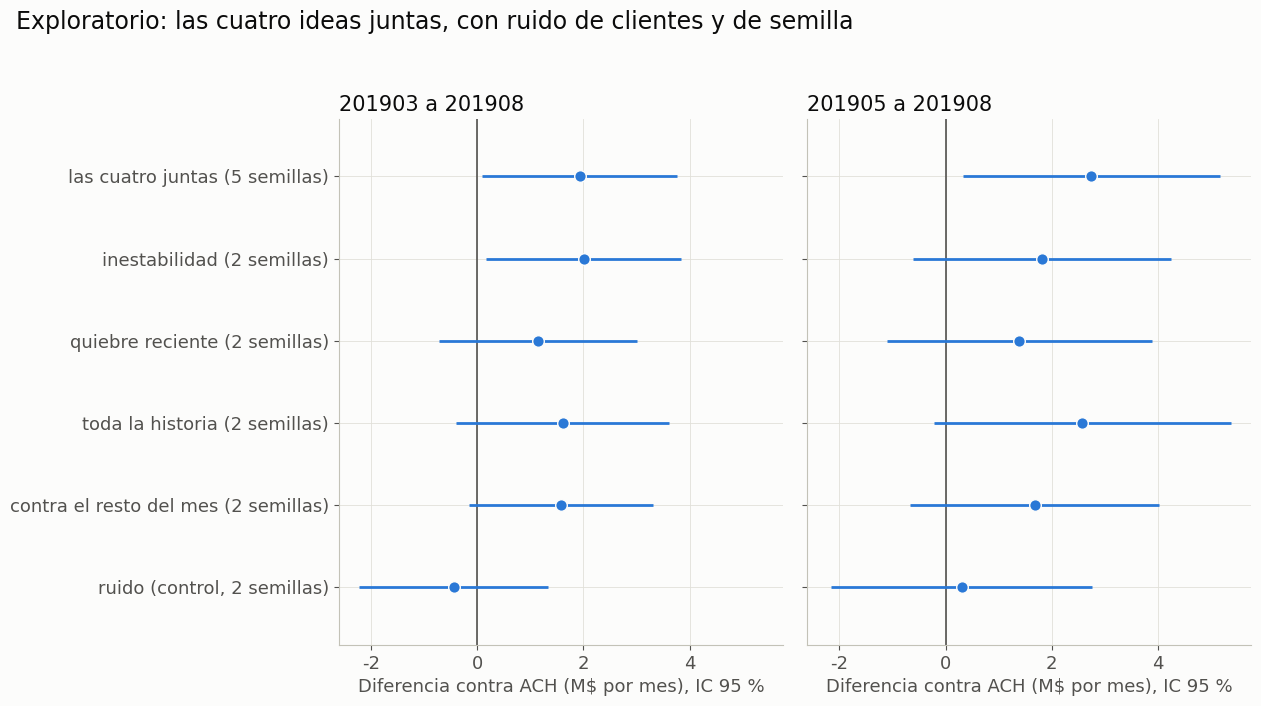

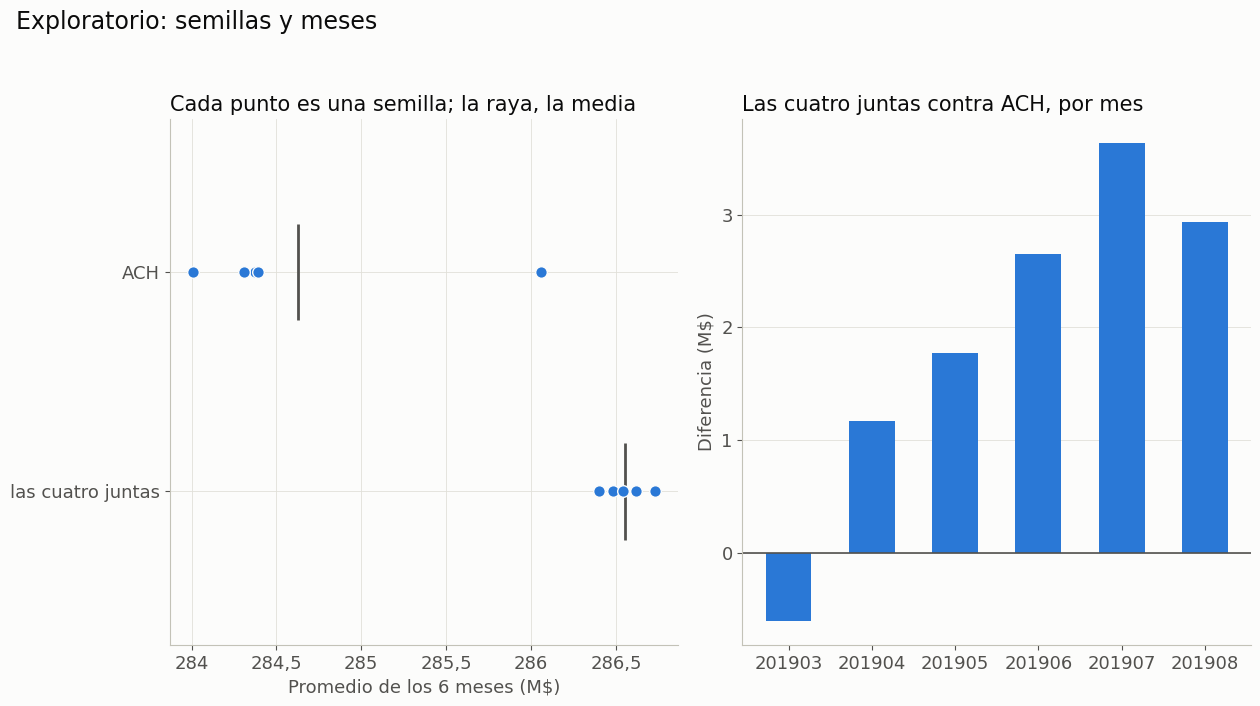

In [7]:
TINTA_2, GRILLA, AZUL = '#52514e', '#e1e0d9', '#2a78d6'
plt.rcParams.update({'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c3c2b7',
                     'axes.labelcolor': TINTA_2, 'xtick.color': TINTA_2, 'ytick.color': TINTA_2, 'text.color': '#0b0b0b',
                     'axes.grid': True, 'grid.color': GRILLA, 'grid.linewidth': 0.6, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 13, 'axes.titlesize': 15})
TAMANO, DPI = (12.8, 7.2), 150


def coma(x, decimales=1):
    return f'{x:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


NOMBRES = {'ACK': 'ruido (control, 2 semillas)', 'ACH_V': 'inestabilidad (2 semillas)', 'ACH_Q': 'quiebre reciente (2 semillas)',
           'ACH_T': 'toda la historia (2 semillas)', 'ACH_Z': 'contra el resto del mes (2 semillas)', 'ACH_4': 'las cuatro juntas (5 semillas)'}
t = comparacion.set_index('config').loc[LISTA]
y = np.arange(len(LISTA))[::-1]
etiquetas = [NOMBRES[c] for c in LISTA]
formato = FuncFormatter(lambda v, _: coma(v, 0 if float(v).is_integer() else 1))

fig, ejes = plt.subplots(1, 2, figsize=TAMANO, sharex=True)
for ax, (d, inf, sup), titulo in zip(ejes, (('d_M', 'ic95_inf_M', 'ic95_sup_M'), ('d4_M', 'ic95_inf4_M', 'ic95_sup4_M')),
                                     ('201903 a 201908', '201905 a 201908')):
    ax.axvline(0, color=TINTA_2, lw=1.2)
    ax.hlines(y, t[inf], t[sup], color=AZUL, lw=2)
    ax.scatter(t[d], y, s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
    ax.set_yticks(y, etiquetas if ax is ejes[0] else [])
    ax.set_ylim(-0.7, len(LISTA) - 0.3)
    ax.xaxis.set_major_formatter(formato)
    ax.set_title(titulo, loc='left')
    ax.set_xlabel('Diferencia contra ACH (M$ por mes), IC 95 %')
fig.suptitle('Exploratorio: las cuatro ideas juntas, con ruido de clientes y de semilla', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '14_1_juntas.png', dpi=DPI)
plt.show()

fig, ejes = plt.subplots(1, 2, figsize=TAMANO)
ax = ejes[0]
for fila_y, c in enumerate([JUNTAS, BASE_CURADA]):
    valores = por_semilla(c, MESES_BANCO)
    ax.scatter(valores, np.full(len(valores), fila_y), s=70, color=AZUL, zorder=3, edgecolor='#fcfcfb')
    ax.vlines(valores.mean(), fila_y - 0.22, fila_y + 0.22, color=TINTA_2, lw=2)
ax.set_yticks([0, 1], ['las cuatro juntas', 'ACH'])
ax.set_ylim(-0.7, 1.7)
ax.xaxis.set_major_formatter(formato)
ax.set_title('Cada punto es una semilla; la raya, la media', loc='left')
ax.set_xlabel('Promedio de los 6 meses (M$)')
ax = ejes[1]
d_mes = [t.loc[JUNTAS, f'd_{m}'] for m in MESES_BANCO]
ax.axhline(0, color=TINTA_2, lw=1.2)
ax.bar([str(m) for m in MESES_BANCO], d_mes, color=AZUL, width=0.55)
ax.yaxis.set_major_formatter(formato)
ax.set_title('Las cuatro juntas contra ACH, por mes', loc='left')
ax.set_ylabel('Diferencia (M$)')
ax.grid(axis='x', visible=False)
ax.set_axisbelow(True)
fig.suptitle('Exploratorio: semillas y meses', x=0.02, ha='left', fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
fig.savefig(FIGURAS / '14_2_semillas_y_meses.png', dpi=DPI)
plt.show()

## 8. Lecturas fijadas antes de correr

| `d` = `ACH_4` − `ACH` | Lectura | Qué se hace después |
|---|---|---|
| +3 M o más | Juntas suman | Separar qué bloques aportan, y probar en 201909 y 201910 con la ventana reciente |
| De +1,5 M a menos de +3 M | Señal intermedia | `ACH_4` queda como vigente sin separar bloques. Se prueba en 201909 y 201910 con la ventana reciente |
| Menos de +1,5 M | Casi agotada | `ACH` sigue como vigente, y se busca dinero en otro lado |

La comparación de cada candidata contra la `ACH` de 5 semillas es descriptiva.

**Control 8:** las salidas anteriores no cambiaron.

In [8]:
assert huella_archivos() == HUELLA_INICIAL, 'Cambiaron las salidas anteriores'   # control 8
print(f'Control de salidas OK · {(time.time() - T_INICIO) / 60:.1f} min en total · memoria máxima {memoria_gb()} GB')
if segundos:
    print('Segundos por modelo:', {c: round(float(np.mean(v)), 1) for c, v in segundos.items()})
print()
print('EXPLORATORIO: no cambia el resultado de la regla pre-registrada.')
print()

r = comparacion.set_index('config').loc[JUNTAS]
if r['d_M'] >= UMBRAL_SUMAN:
    lectura = 'Juntas suman'
elif r['d_M'] >= UMBRAL_INTERMEDIO:
    lectura = 'Señal intermedia'
else:
    lectura = 'Casi agotada'
print(f'1. ACH_4 contra ACH: {r["d_M"]:+.2f} M ({r["ic95_inf_M"]:.2f} a {r["ic95_sup_M"]:.2f}) · lectura: {lectura}')
print(f'   Error total {r["error_total_M"]:.2f} M: clientes {r["error_clientes_M"]:.2f} M y semilla {r["error_semilla_M"]:.2f} M')
print(f'   201905-08: {r["d4_M"]:+.2f} M ({r["ic95_inf4_M"]:.2f} a {r["ic95_sup4_M"]:.2f}) · ensamble de 5 semillas: {r["d_ensamble_M"]:+.2f} M')
print(f'   Semillas de ACH_4 sobre la media de ACH: {int((por_semilla(JUNTAS, MESES_BANCO) > media_meses(BASE_CURADA, MESES_BANCO)).sum())} de {N_SEMILLAS}')
print()
print('2. Descriptivo: cada una, con 2 semillas, contra ACH con 5')
for c in CANDIDATAS + [RUIDO]:
    q = comparacion.set_index('config').loc[c]
    print(f'   {c}: {q["d_M"]:+.2f} M ({q["ic95_inf_M"]:.2f} a {q["ic95_sup_M"]:.2f}) · 201905-08: {q["d4_M"]:+.2f} M')

iteraciones = pd.DataFrame([{
    'config': c, 'hipotesis': HIPOTESIS[c], 'columnas_nuevas': ESPERADO_N_VARIABLES[c] - ESPERADO_N_VARIABLES[BASE_CURADA],
    'ganancia_banda_M': round(media_meses(c, MESES_BANCO), 3),
    'd_contra_ACH_M': round(r['d_M'], 3) if c == JUNTAS else np.nan,
    'resultado': lectura if c == JUNTAS else 'base',
} for c in CONFIGS])
iteraciones.to_csv(RESULTADOS / '14_iteraciones.tsv', sep='\t', index=False)

Control de salidas OK · 38.6 min en total · memoria máxima 6.4 GB
Segundos por modelo: {'ACH': 44.3, 'ACH_4': 59.9}

EXPLORATORIO: no cambia el resultado de la regla pre-registrada.

1. ACH_4 contra ACH: +1.93 M (0.09 a 3.77) · lectura: Señal intermedia
   Error total 0.94 M: clientes 0.86 M y semilla 0.37 M
   201905-08: +2.75 M (0.32 a 5.17) · ensamble de 5 semillas: +1.98 M
   Semillas de ACH_4 sobre la media de ACH: 5 de 5

2. Descriptivo: cada una, con 2 semillas, contra ACH con 5
   ACH_V: +2.00 M (0.17 a 3.84) · 201905-08: +1.82 M
   ACH_Q: +1.14 M (-0.73 a 3.01) · 201905-08: +1.39 M
   ACH_T: +1.61 M (-0.40 a 3.62) · 201905-08: +2.58 M
   ACH_Z: +1.58 M (-0.15 a 3.31) · 201905-08: +1.68 M
   ACK: -0.45 M (-2.23 a 1.33) · 201905-08: +0.31 M
